<a href="https://colab.research.google.com/github/wavejumper3/Machine-Learning-349/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Task 1:
### Load the dataset into a Pandas DataFrame.

This is done using the exact code from the UCI website, plus a line at the start that installs the library they use, and one to concatenate its result into a pandas dataframe.

In [3]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.concat([X, y], axis=1)


# Task 2:
### Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

I don't think theres anything I can add here, this is exactly what was asked.
I added the newlines in the non-primary print statements to space these out a little, which looks nicer.

In [5]:
print("head")
display(df.head())
print("\n\ninfo")
df.info()
print("\n\ndescription")
display(df.describe())

head


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0




info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


description


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



# Task 3:
### Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.

I made a cleaner version of the dataframe, making sure all null values were np.nan.
I then printed out how many null values each column had. Once I had that, I used my imputer to replace those column's nan values with the median values for those columns. This was easier because they were all numerical columns.

I chose the variable name "cleaner_df" because while it's not completely clean, its better, and made the final check an if statement so it's easier to check at a glance.

In [17]:
from sklearn.impute import SimpleImputer
import numpy as np
imputate = SimpleImputer(strategy='median')

cleaner_df = df.replace("?", np.nan)
#used to check what values needed to be imputed
print("Null values:")
display(cleaner_df.isna().sum())

print("cleaning...")
bad_ones = ['ca', 'thal']
cleaner_df[bad_ones] = imputate.fit_transform(full_df[bad_ones])

# sanity check
if cleaner_df.isna().sum().sum() == 0:
  print("no more missing values!!!")
else:
  print("I did something wrong, figure it out")

Null values:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


cleaning...
no more missing values!!!



# Task 4:
### Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

I looked back at homework 3 for this, and it still works! I create a transformer for selecting each, then a transformer for "scaling" (which also encodes the categorical values... perhaps there's a better word for that combination step. I'll find it later, currently there's homework due.)

My pipeline consists of a step that selects each column to seperate them, then a second step to apply the needed function to each category.

In [108]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline


num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

transformer = ColumnTransformer(
  transformers=[
    ("number_rule", num_imputer, make_column_selector(dtype_include=np.number)),
    ("word_rule", cat_imputer, make_column_selector(dtype_include=object),),
  ]
)
transformer.set_output(transform="pandas") #this is exactly the same as homework 3

scaling_pipeline = ColumnTransformer([
    ("num", StandardScaler(), make_column_selector(dtype_include=np.number)),
    ("cat", OneHotEncoder(sparse_output=False), make_column_selector(dtype_include=object),)
])
scaling_pipeline.set_output(transform="pandas")

full_pipeline = make_pipeline(
    transformer,
    scaling_pipeline,
)
df_usable = full_pipeline.fit_transform(cleaner_df)

     num__number_rule__age  num__number_rule__sex  num__number_rule__cp  \
0                 0.948726               0.686202             -2.251775   
1                 1.392002               0.686202              0.877985   
2                 1.392002               0.686202              0.877985   
3                -1.932564               0.686202             -0.165268   
4                -1.489288              -1.457296             -1.208521   
..                     ...                    ...                   ...   
298              -1.046013               0.686202             -2.251775   
299               1.502821               0.686202              0.877985   
300               0.283813               0.686202              0.877985   
301               0.283813              -1.457296             -1.208521   
302              -1.821745               0.686202             -0.165268   

     num__number_rule__trestbps  num__number_rule__chol  \
0                      0.757525         


# Task 5:
### Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.


...and now we draw the rest of the owl. (joke term I use for a when single step at contains the meat of an assignment or task).

first I created the pipeline as asked.

then, I split our data into our predicted variable and the inputs. You'll see i changed the Y values, that's because the roc auc score only works with binary output problems, as far as I can tell, so I made the problem binary so it would work.

confusion matrix

[[32  4]
 [11 14]]


classification report

              precision    recall  f1-score   support

           0       0.74      0.89      0.81        36
           1       0.78      0.56      0.65        25

    accuracy                           0.75        61
   macro avg       0.76      0.72      0.73        61
weighted avg       0.76      0.75      0.74        61



roc auc score

0.8566666666666666


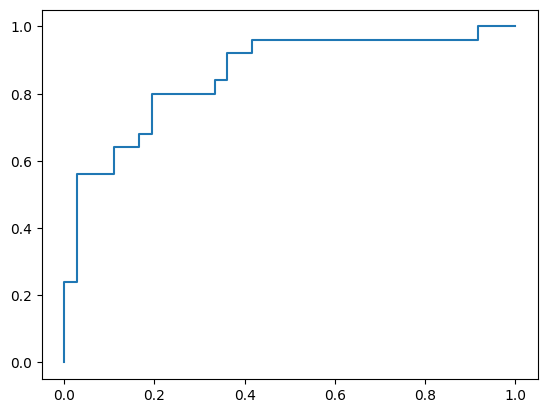

In [111]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve


svc_pipeline = Pipeline(steps=[
    ('full_pipeline', full_pipeline),
    ('svc', SVC(kernel='rbf', probability=True)),
])
y = [int(bool(num)) for num in cleaner_df['ca']] # if num is zero, it stays zero, otherwise its one!
X = cleaner_df.drop(columns=["ca"])


X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=.2, stratify=y
)

svc = svc_pipeline.fit(X_train, y_train)
y_pred = svc_pipeline.predict(X_test)
y_prob = svc_pipeline.predict_proba(X_test)[:, 1]

print("confusion matrix\n")
print(confusion_matrix(y_test, y_pred))
print("\n\nclassification report\n")
print(classification_report(y_test, y_pred))
print("\n\nroc auc score\n")
print(roc_auc_score(y_test, y_prob))


import matplotlib.pyplot as plt

auc_score = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)


# Task 6:
Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

confusion matrix

[[25 11]
 [ 5 20]]


classification report

              precision    recall  f1-score   support

           0       0.83      0.69      0.76        36
           1       0.65      0.80      0.71        25

    accuracy                           0.74        61
   macro avg       0.74      0.75      0.74        61
weighted avg       0.76      0.74      0.74        61



roc auc score

0.7655555555555555


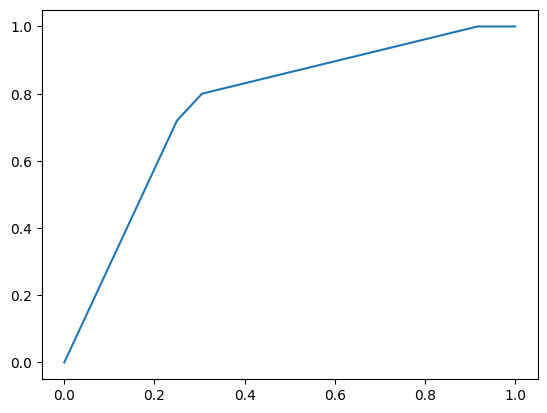

In [101]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline(steps=[
    ('full_pipeline', full_pipeline),
    ('dt', DecisionTreeClassifier(max_depth=2)),
])

tree = tree_pipeline.fit(X_train, y_train)
y_pred = tree_pipeline.predict(X_test)
y_prob = tree_pipeline.predict_proba(X_test)[:, 1]

print("confusion matrix\n")
print(confusion_matrix(y_test, y_pred))
print("\n\nclassification report\n")
print(classification_report(y_test, y_pred))
print("\n\nroc auc score\n")
print(roc_auc_score(y_test, y_prob))

import matplotlib.pyplot as plt

auc_score = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)


# Task 7:
### Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

I made a param grid with some unit values, then made a gridsearcher! I printed out the parameters.
Every time it was one of the extreme values of the grid (highest or lowest), I added the next order of magnitude until that stopped happening.

In [102]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [1000, 100,10,1,.1,.01],
    'gamma': [1, .1, .01, .001, .0001, .00001],
}

gridsearch = GridSearchCV(estimator = svc_pipeline['svc'], param_grid = param_grid)
gridsearch.fit(X_train, y_train)

print("use these parameters:")
print(gridsearch.best_params_) # why on earth does that end with an underscore? I should check on this, maybe its some convention

use these parameters:
{'C': 1000, 'gamma': 1e-05}



# Task 8:
### Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

I inspected feature importances by generating the list, then printing  out all values in order.
I then realized the most important feature was labeled "num" (definitely incorrect), so i set x to the original feature names again and that fixed it.


If you go up from the bottom, that's the order it checks different variables in, as you go down the tree. So, it checks thal first, and then age.
The reason the tree is so shallow is that above, smaller trees actually gave higher roc auc values, which while confusing, I had to go with.


In [112]:
from sklearn.tree import plot_tree

x = heart_disease.data.features

important_features = pd.Series(tree_pipeline['dt'].feature_importances_, index=x.columns) #another underscore variable.
print("How important various things are:\n")
print(important_features.sort_values())

How important various things are:

sex         0.000000
cp          0.000000
trestbps    0.000000
chol        0.000000
restecg     0.000000
fbs         0.000000
thalach     0.000000
exang       0.000000
slope       0.000000
oldpeak     0.000000
ca          0.000000
age         0.296119
thal        0.703881
dtype: float64
